# 06 — Model Evaluation (V3: Learning Rate Scheduler)

## Objective

Evaluate **the saved V3 checkpoint** after checking that validation performance is reproducible.

This notebook:

1. Loads `models/experiments/v3_scheduler/best_cnn.keras`.
2. Loads the **unchanged** stratified split manifest.
3. Rechecks validation metrics against V3 training history (detect model/pipeline mismatches).
4. Evaluates the held-out test set and builds a confusion matrix and classification report.
5. Saves the report inside the **V3 experiment directory**, without overwriting V1 reports.
6. Shows correctly and incorrectly classified test images.

**Important:** Validation is for model selection. The test set is for final evaluation, not repeated architecture tuning. These results do not establish clinical safety; patient-level independence has not been verified.


In [1]:
from pathlib import Path
import math
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Works when Jupyter is launched from the project's notebooks/ or project root.
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if not (PROJECT_ROOT / "src" / "brainscan.py").is_file():
    raise FileNotFoundError(
        f"Cannot find src/brainscan.py below {PROJECT_ROOT}. "
        "Launch Jupyter from your project's notebooks/ directory or its root."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.brainscan import create_dataset, preprocess_image, CLASS_NAMES, CLASS_TO_ID

V3_DIR = PROJECT_ROOT / "models" / "experiments" / "v3_scheduler"
MODEL_PATH = V3_DIR / "best_cnn.keras"
HISTORY_PATH = V3_DIR / "training_history.csv"

if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"V3 checkpoint not found: {MODEL_PATH}")

model = tf.keras.models.load_model(MODEL_PATH)
print("Loaded checkpoint:", MODEL_PATH)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Class mapping:", CLASS_TO_ID)

assert model.input_shape[1:] == (224, 224, 1), "Unexpected CNN input shape"
assert model.output_shape[-1] == len(CLASS_NAMES), "Class-count mismatch"


I0000 00:00:1792170199.253906  160501 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792170199.308471  160501 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792170200.457533  160501 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1792170201.547641  160501 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute c

Loaded checkpoint: /home/houssam/Desktop/Briefs/Brief 4/models/experiments/v3_scheduler/best_cnn.keras
Input shape: (None, 224, 224, 1)
Output shape: (None, 4)
Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


## 1 — Load and validate the split manifest

Use the same manifest as during V3 training. Ensure image paths and class labels are valid, and that test records remain in a deterministic order.

In [2]:
MANIFEST_PATH = PROJECT_ROOT / "data" / "splits" / "split_manifest.csv"
manifest = pd.read_csv(MANIFEST_PATH)
required_cols = {"path", "label", "split"}
if not required_cols.issubset(manifest.columns):
    raise ValueError(f"Manifest must contain: {sorted(required_cols)}")

manifest = manifest.copy()
for column in ("path", "label", "split"):
    if manifest[column].isna().any():
        raise ValueError(f"Missing values in manifest column: {column}")
    manifest[column] = manifest[column].astype(str).str.strip()

valid_splits = {"train", "validation", "test"}
if not set(manifest["split"]).issubset(valid_splits):
    raise ValueError(f"Unexpected splits: {set(manifest['split']) - valid_splits}")
if not set(manifest["label"]).issubset(set(CLASS_NAMES)):
    raise ValueError(f"Unexpected labels: {set(manifest['label']) - set(CLASS_NAMES)}")
if manifest["path"].duplicated().any():
    raise ValueError("Same path occurs more than once across the split manifest")

# Path existence is checked before starting GPU evaluation.
missing_paths = [
    relative_path for relative_path in manifest["path"]
    if not (PROJECT_ROOT / relative_path).is_file()
]
if missing_paths:
    raise FileNotFoundError(f"{len(missing_paths)} image paths missing, e.g. {missing_paths[:3]}")

def get_records(split_name):
    subset = manifest.loc[manifest["split"] == split_name]
    return [
        (PROJECT_ROOT / row.path, row.label)
        for row in subset.itertuples(index=False)
    ]

val_records = get_records("validation")
test_records = get_records("test")
if not val_records or not test_records:
    raise ValueError("Validation and test splits must be nonempty")

BATCH_SIZE = 32

def make_eval_dataset(records):
    ds = create_dataset(records, training=False, batch_size=BATCH_SIZE)
    # The Python generator normally has unknown cardinality; tell Keras exactly
    # how many batches to expect and detect generator truncation.
    expected_batches = math.ceil(len(records) / BATCH_SIZE)
    return ds.apply(tf.data.experimental.assert_cardinality(expected_batches))

val_ds = make_eval_dataset(val_records)
test_ds = make_eval_dataset(test_records)

print("Split counts:")
print(manifest["split"].value_counts().to_string())
print("\nTest class counts:")
print(manifest.loc[manifest["split"] == "test", "label"].value_counts().to_string())


Split counts:
split
train         4708
validation    1009
test          1009

Test class counts:
label
pituitary     261
notumor       259
meningioma    246
glioma        243


## 2 — Reproduce validation performance

V3 training reported ~92.96% validation accuracy and a validation loss of ~0.2159 for its best checkpoint. This check matters more than a direct test comparison: if the saved V3 model cannot reproduce its validation results, inspect the checkpoint or input pipeline first.

In [3]:
val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)
print(f"Saved V3 checkpoint — validation accuracy: {val_accuracy:.2%}")
print(f"Saved V3 checkpoint — validation loss:     {val_loss:.4f}")

if HISTORY_PATH.is_file():
    history_df = pd.read_csv(HISTORY_PATH)
    best_idx = history_df["val_loss"].idxmin()
    expected_acc = float(history_df.loc[best_idx, "val_accuracy"])
    expected_loss = float(history_df.loc[best_idx, "val_loss"])
    print(f"V3 history — best epoch: {best_idx + 1}")
    print(f"V3 history — validation accuracy: {expected_acc:.2%}")
    print(f"V3 history — validation loss:     {expected_loss:.4f}")
    if abs(val_accuracy - expected_acc) > 0.01 or abs(val_loss - expected_loss) > 0.05:
        print("WARNING: V3 checkpoint validation does NOT match its saved history.")
        print("Check the checkpoint, split manifest and preprocessing version before interpreting test accuracy.")
    else:
        print("V3 validation performance reproduces its saved training history.")
else:
    print(f"NOTE: No training history found at {HISTORY_PATH}")


I0000 00:00:1792170210.711583  160501 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1792170210.999435  160756 service.cc:153] XLA service 0x7ff5e0072fa0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792170210.999453  160756 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5070 Laptop GPU, Compute Capability 12.0a (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792170211.011313  160756 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792170211.071235  160756 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1792170213.054973  160756 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Saved V3 checkpoint — validation accuracy: 92.96%
Saved V3 checkpoint — validation loss:     0.2159
V3 history — best epoch: 15
V3 history — validation accuracy: 92.96%
V3 history — validation loss:     0.2159
V3 validation performance reproduces its saved training history.


## 3 — Final test evaluation

Do **not** retrain the model here. These metrics use V3 weights exactly as saved.

In [4]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
print(f"V3 test accuracy: {test_accuracy:.2%}")
print(f"V3 test loss:     {test_loss:.4f}")
print(f"Validation-to-test accuracy gap: {(val_accuracy - test_accuracy) * 100:+.2f} percentage points")


V3 test accuracy: 91.58%
V3 test loss:     0.2170
Validation-to-test accuracy gap: +1.39 percentage points


## 4 — Predictions, classification report and confusion matrix

Collect predicted probabilities and ground-truth labels **from the same test batches**. This guarantees label-prediction alignment and avoids the `model.predict()` warning seen with generators of unknown length.

Test accuracy from predictions: 91.58%

Classification report:
               precision    recall  f1-score   support

      glioma      0.831     0.971     0.896       243
  meningioma      0.887     0.764     0.821       246
     notumor      0.984     0.934     0.958       259
   pituitary      0.966     0.989     0.977       261

    accuracy                          0.916      1009
   macro avg      0.917     0.915     0.913      1009
weighted avg      0.919     0.916     0.915      1009



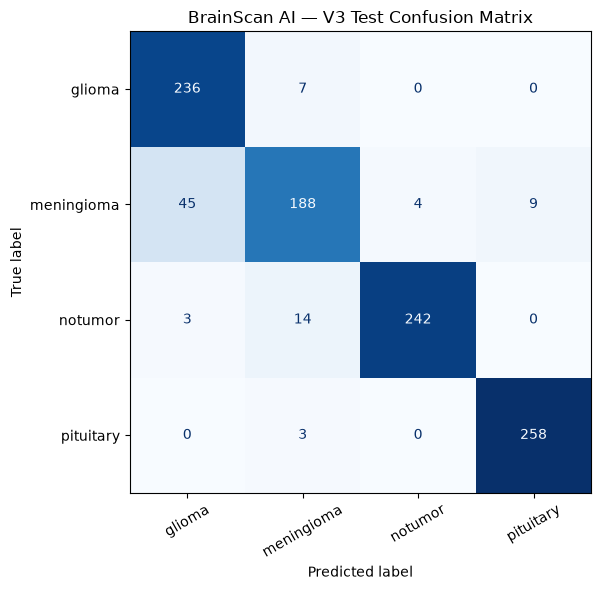

Report saved: /home/houssam/Desktop/Briefs/Brief 4/models/experiments/v3_scheduler/test_report.txt
Confusion matrix saved: /home/houssam/Desktop/Briefs/Brief 4/models/experiments/v3_scheduler/confusion_matrix.png


In [5]:
probability_batches = []
true_batches = []

for image_batch, label_batch in test_ds:
    scores = model(image_batch, training=False).numpy()
    probability_batches.append(scores)
    true_batches.append(label_batch.numpy())

probabilities = np.concatenate(probability_batches, axis=0)
y_true = np.concatenate(true_batches, axis=0).astype(int)
y_pred = np.argmax(probabilities, axis=1)

assert len(y_true) == len(test_records), "Prediction count does not match test manifest"
assert probabilities.shape == (len(test_records), len(CLASS_NAMES))

calculated_accuracy = accuracy_score(y_true, y_pred)
print(f"Test accuracy from predictions: {calculated_accuracy:.2%}")
if not np.isclose(calculated_accuracy, test_accuracy, atol=1e-3):
    raise AssertionError("Accuracy mismatch: model.evaluate and manually collected predictions disagree")

report = classification_report(
    y_true, y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0,
)
print("\nClassification report:\n", report)

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", values_format="d", xticks_rotation=30, colorbar=False
)
ax.set_title("BrainScan AI — V3 Test Confusion Matrix")
fig.tight_layout()
fig.savefig(V3_DIR / "confusion_matrix.png", dpi=160)
plt.show()

report_path = V3_DIR / "test_report.txt"
report_path.write_text(
    f"Model: {MODEL_PATH}\n"
    f"Validation accuracy: {val_accuracy:.6f}\n"
    f"Validation loss: {val_loss:.6f}\n"
    f"Test accuracy: {test_accuracy:.6f}\n"
    f"Test loss: {test_loss:.6f}\n"
    f"Test images: {len(test_records)}\n\n"
    f"{report}\n"
    f"Confusion matrix (rows=true, cols=predicted):\n{cm}\n",
    encoding="utf-8",
)
print("Report saved:", report_path)
print("Confusion matrix saved:", V3_DIR / "confusion_matrix.png")


## 5 — Inspect mistakes

Reviewing false predictions is more useful than relying on accuracy alone. The displayed order matches the unshuffled test manifest.

Correct: 924 | Incorrect: 85


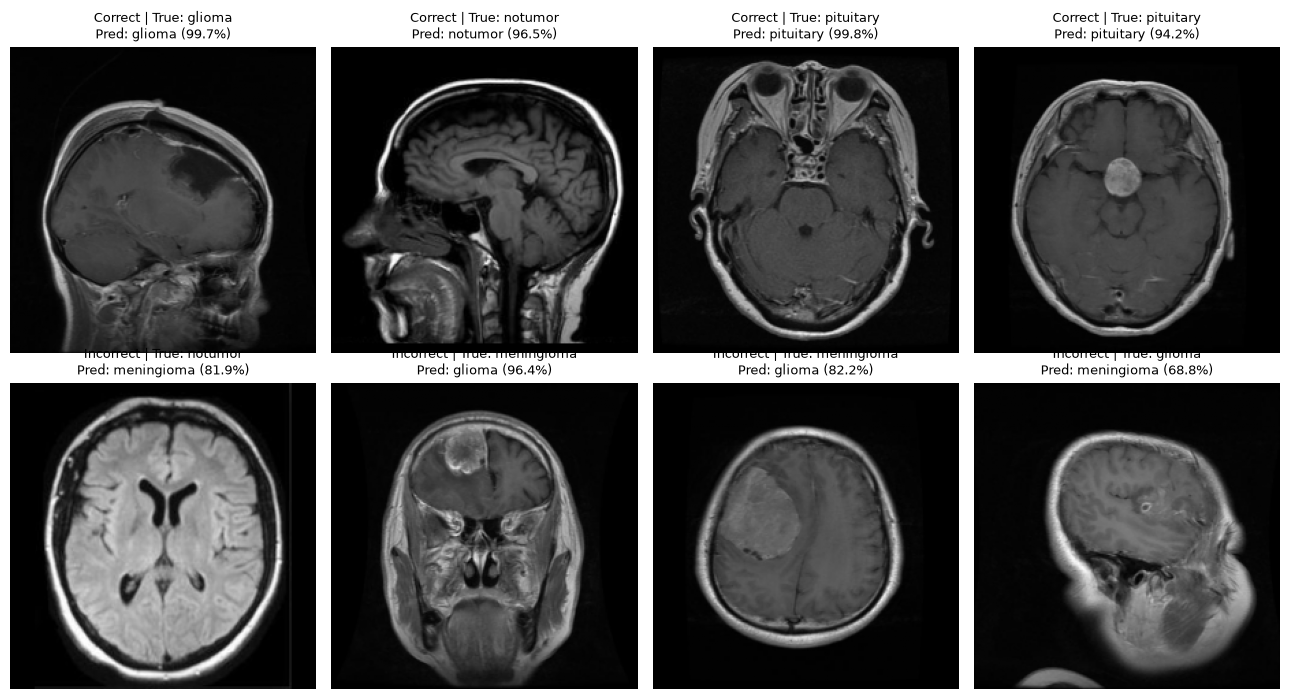

In [6]:
correct_idx = np.flatnonzero(y_true == y_pred)
incorrect_idx = np.flatnonzero(y_true != y_pred)
print(f"Correct: {len(correct_idx)} | Incorrect: {len(incorrect_idx)}")

rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for row, (case_name, indices) in enumerate([
    ("Correct", correct_idx),
    ("Incorrect", incorrect_idx),
]):
    chosen = rng.choice(indices, size=min(4, len(indices)), replace=False) if len(indices) else []
    for col, ax in enumerate(axes[row]):
        ax.axis("off")
        if col >= len(chosen):
            continue
        idx = int(chosen[col])
        path, _ = test_records[idx]
        img = preprocess_image(path)
        ax.imshow(img.squeeze(), cmap="gray", vmin=0, vmax=1)
        confidence = float(np.max(probabilities[idx]))
        ax.set_title(
            f"{case_name} | True: {CLASS_NAMES[y_true[idx]]}\n"
            f"Pred: {CLASS_NAMES[y_pred[idx]]} ({confidence:.1%})",
            fontsize=9,
        )
fig.tight_layout()
plt.show()
